# Oso (SR530) landslide: lidar change detection and sediment budget

Pre-event lidar (PSLC, 2013) against post-event lidar (WSDOT, spring 2014) of the 22 March 2014 SR530 landslide
near Oso, Washington. This notebook runs the workflow of the `oso_cd` package step by step; every parameter is in
`config/oso.toml`. Data sources, licences and references: see `README.md` and `data/README.md`.

Data: Puget Sound LiDAR Consortium (2013 Tulalip Partnership, public domain) and Washington State Department of
Transportation (2014 Oso / Stillaguamish lidar by Quantum Spatial, freely available through PSLC). The raw lidar is
not redistributed in this repository.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

from oso_cd import pipeline

CONFIG = Path("..") / "config" / "oso.toml"
cfg = pipeline.load_config(CONFIG)
t0, t1 = cfg["labels"]["t0"], cfg["labels"]["t1"]

## 0. Units: the tiles say metres but hold feet

Both epochs carry EPSG:32148 (NAD83 / Washington North, *metres*) in their GeoKeys, but X, Y and Z are in US survey
feet (the 2014 vendor report says so, and the Z range of 235-1,070 matches the valley floor at Oso only in feet).
Read as labelled, vertical change would be ×3.28 too large and volumes ×35.3, and a check on the EPSG code would
pass. The PDAL pipeline overrides the CRS with NAD83 / Washington North (ftUS) + NAVD88 (ftUS), converts to metres on
the same datum and keeps the ground class (ASPRS 2).

In [2]:
ground = pipeline.step_prepare(cfg)
# The pipeline as run (stage types and CRS only: the recorded JSON holds local file paths)
stages = json.loads((cfg["paths"]["work"] / f"{t1}_prepare_pipeline.json").read_text())["pipeline"]
for s in stages:
    print(s["type"], s.get("override_srs") or s.get("out_srs") or s.get("limits") or "")

readers.las EPSG:2285+6360
filters.reprojection EPSG:32148+5703
filters.range Classification[2:2]
writers.las 


## 1. Registration on stable terrain

The 2014 ground cloud is aligned to the 2013 one with py4dgeo's stable-area ICP: both clouds are thinned to one
point per 1 m voxel, supervoxels that changed less than 0.2 m are taken as stable, and a point-to-plane ICP is fitted
on them. At Oso the residual offset between the two surveys is a few centimetres.

In [3]:
registered = pipeline.step_register(cfg, ground)
reg = json.loads((cfg["paths"]["results"] / "registration.json").read_text())
print("translation (m):", [round(v, 3) for v in reg["translation_m"]])

translation (m): [-0.038, -0.053, -0.087]


## 2. Ground DTMs (1 m) with a record of what is measured

Inverse-distance gridding of the ground points within res/√2 of each cell centre, then a GDAL inverse-distance fill
of the empty cells inside the common survey footprint. Under the forest, the 2013 survey has few ground returns, so a
large share of its cells is interpolated: each DTM comes with a source mask (measured / interpolated) and the
distance to the nearest measured cell.

In [4]:
dtms = pipeline.step_dtm(cfg, {t0: ground[t0], t1: registered})
pd.DataFrame(json.loads((cfg["paths"]["results"] / "dtm_summary.json").read_text())["epochs"]).T

,cells,measured_pct,mean_points_per_measured_cell,max_interp_distance_m
2013,8268925.0,64.404478,2.938533,12.165525
2014,8268925.0,71.898233,3.497351,39.698866


## 2b. Water: where the DTM shows water, not ground

The debris dammed the river: in April 2014 an impoundment lake covered the upstream end of the deposit, and the river
had started to cut a new channel through it. A ground DTM has no ground under water, so the DoD would count the water
level as deposit. Each epoch gets a water mask on the DTM grid: the 2014 delivery classifies water (ASPRS class 9),
so its mask comes from those points (gaps between sparse returns closed, 1 m buffer for the shore); the 2013 delivery
has no water class, so its river channel was drawn (`inputs/water_2013.gpkg`). In the budget, cells where 2014 is
water are left out and reported apart; cells that were water in 2013 only (the old channel, now buried) are kept and
flagged, because the deposit there is underestimated by the 2013 water depth.

In [5]:
water_masks = pipeline.step_water(cfg, dtms)
pd.DataFrame(water_masks["summary"]).T

,source,water_points,water_area_m2
2013,polygon drawn for 2013 (water_2013.gpkg),0,175611.0
2014,points of ASPRS classes [9],666631,166323.0


## 3. Error model and Level of Detection

On hand-drawn stable areas the true change is zero, so the raw DoD there is error. Its spread (NMAD) grows with
slope and is fitted as σ_DoD(θ) = √(a² + (b·tanθ)²); interpolated cells get an extra term that depends on the
distance to the nearest measured cell, and the spread of the per-area medians gives the systematic error σ_sys.
Each cell is significant when |ΔZ| > 1.96 · √(σ₀² + σ₁²) (95 %). Cells steeper than 45° have no σ and never count.

In [6]:
change = pipeline.step_change(cfg, dtms, water_masks)
em = change["error_model"]
print(f"a = {em['slope_model']['a_m']:.3f} m, b = {em['slope_model']['b_m']:.3f} m, "
      f"sigma_sys = {em['systematic']['sigma_sys_m']:.3f} m, median LoD = {em['lod_median_m']:.2f} m")
print(f"stable areas: NMAD measured {em['stable_measured_nmad_m']:.3f} m, "
      f"interpolated {em['stable_interpolated_nmad_m']:.3f} m, median offset {em['stable_measured_median_m']:+.3f} m")

a = 0.061 m, b = 0.279 m, sigma_sys = 0.028 m, median LoD = 0.33 m
stable areas: NMAD measured 0.094 m, interpolated 0.214 m, median offset +0.009 m


## 4. Sediment budget by zone

Zones: the USGS approximate extent of the deposit (runout, Haugerud 2014) and the source area behind the headscarp.
Volumes are summed over significant cells only and split into cells measured in both epochs and cells interpolated
in at least one, because interpolation is the largest uncertainty after the zone outlines. With the water masks, two more parts are listed: `water_t1_left_out`
(the change left out where 2014 is water, not in the total) and `water_t0_only` (the change kept in the old 2013
channel, inside the total).

In [7]:
display(change["volumes"].round(0))
display(change["uncertainty"].round(0))

,zone,part,zone_area_m2,erosion_m3,deposition_m3,net_m3,erosion_area_m2,deposition_area_m2
0,runout,total,899758.0,341519.0,3784268.0,3442749.0,77955.0,656900.0
1,runout,measured,899758.0,196388.0,2863161.0,2666773.0,50304.0,492032.0
2,runout,interpolated,899758.0,145131.0,921108.0,775977.0,27651.0,164868.0
3,runout,water_t0_only,899758.0,46.0,719341.0,719295.0,97.0,82779.0
4,runout,water_t1_left_out,899758.0,11619.0,197863.0,186245.0,4770.0,61538.0
5,source,total,174954.0,3921392.0,35857.0,-3885535.0,112134.0,18036.0
6,source,measured,174954.0,1385798.0,21182.0,-1364615.0,47174.0,10635.0
7,source,interpolated,174954.0,2535594.0,14674.0,-2520920.0,64960.0,7401.0
8,source,water_t0_only,174954.0,-0.0,0.0,0.0,0.0,0.0
9,source,water_t1_left_out,174954.0,187.0,62.0,-125.0,50.0,49.0


,zone,net_m3,systematic_m3,interpolation_stable_m3,interpolation_conservative_m3,stated_uncertainty_m3,interpolated_share_of_net_pct
0,runout,3442749.0,25464.0,41201.0,192519.0,217983.0,23.0
1,source,-3885535.0,4951.0,15486.0,72361.0,77312.0,65.0


## 5. Check against the reference run and figures

The same budget was first computed with the author's in-house toolbox (v0.7.0, with the same water masks). This
lean implementation must reproduce its zonal net volumes within the tolerances of `config/oso.toml`.

,zone,reference_net_m3,this_net_m3,rel_diff,rel_tol,note
0,runout,3.461669e+06,3.442749e+06,0.005465,0.05,
1,source,-3.883073e+06,-3.885535e+06,0.000634,0.02,


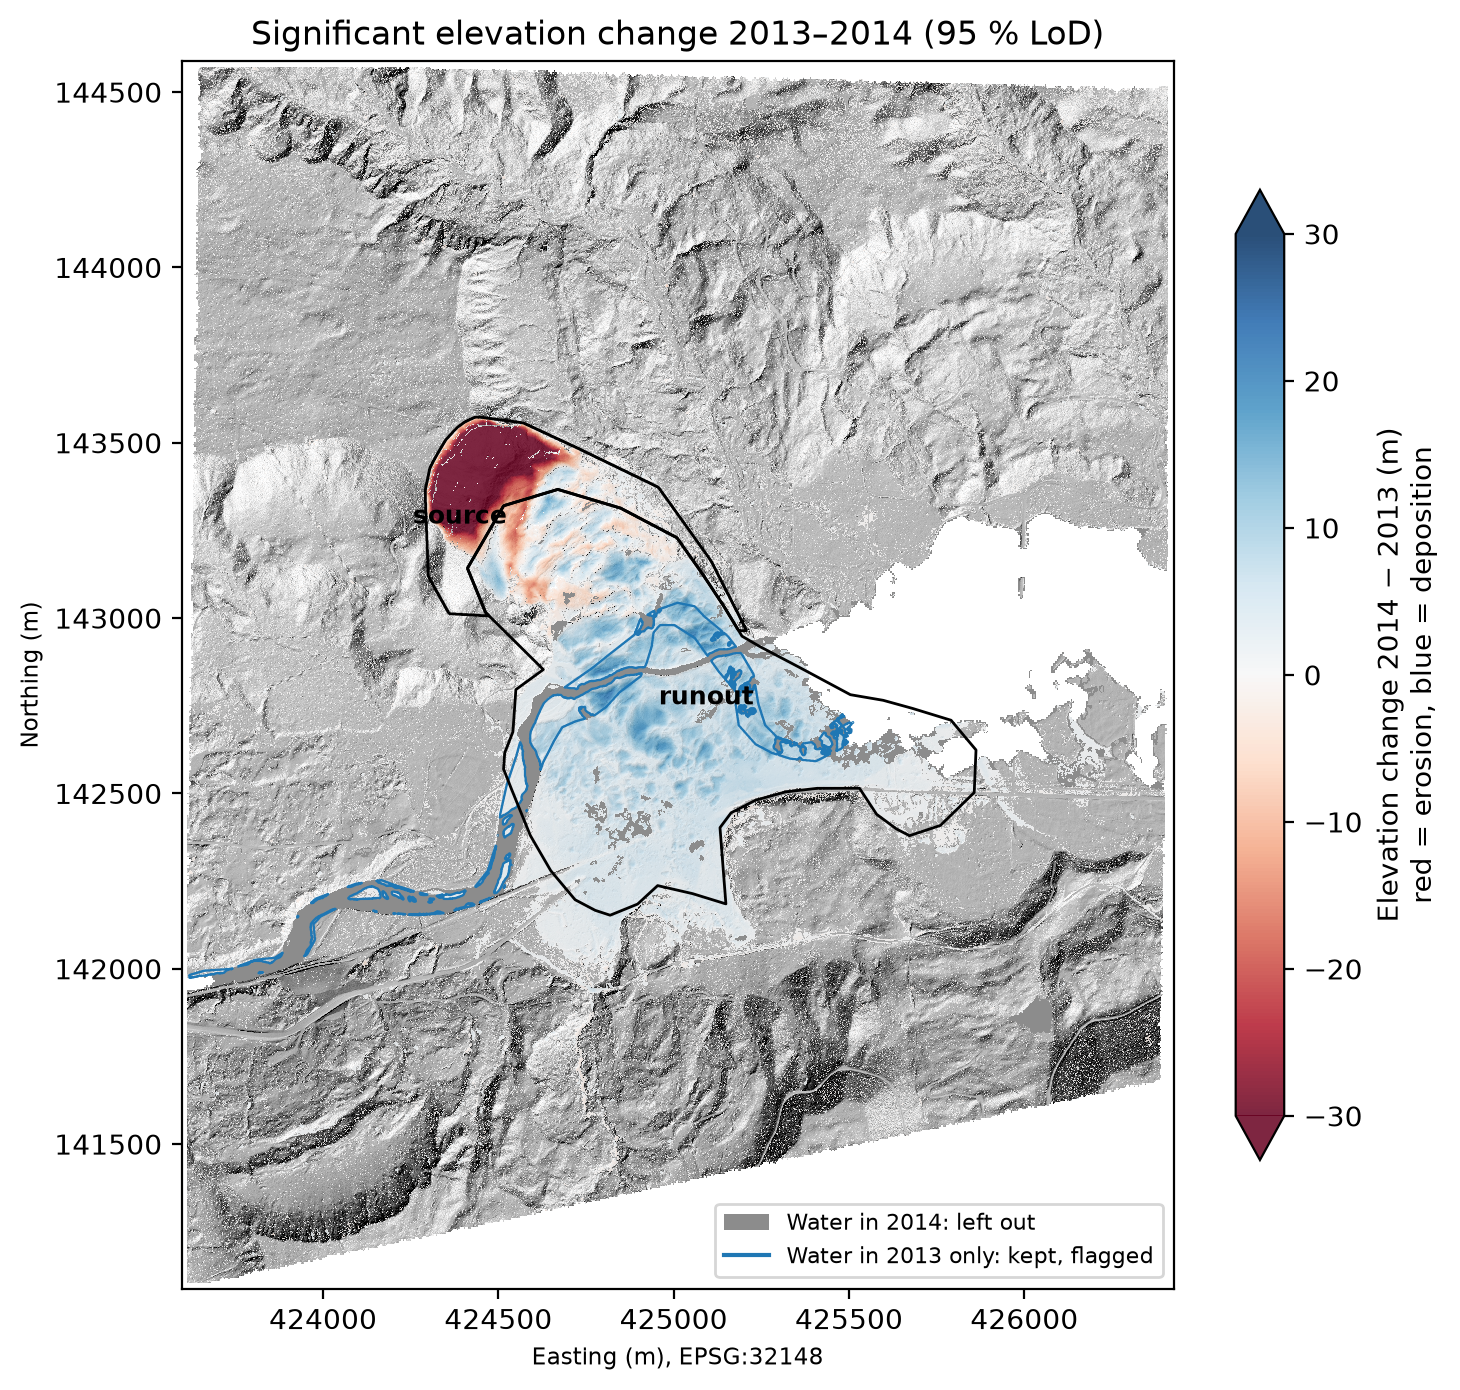

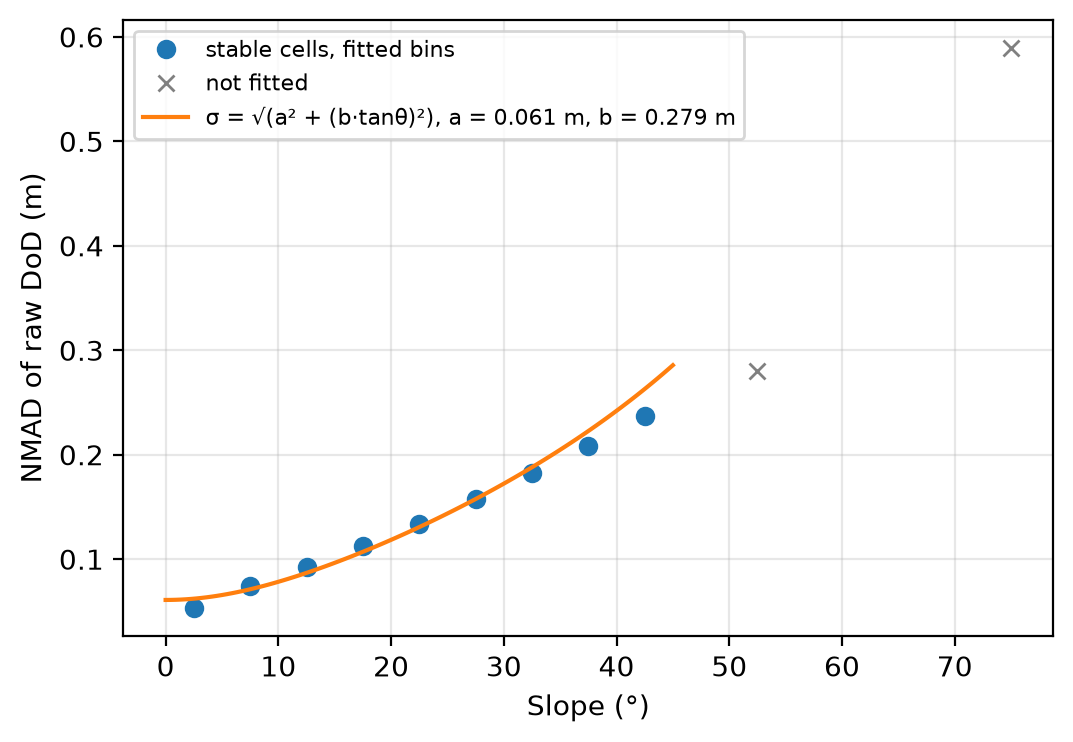

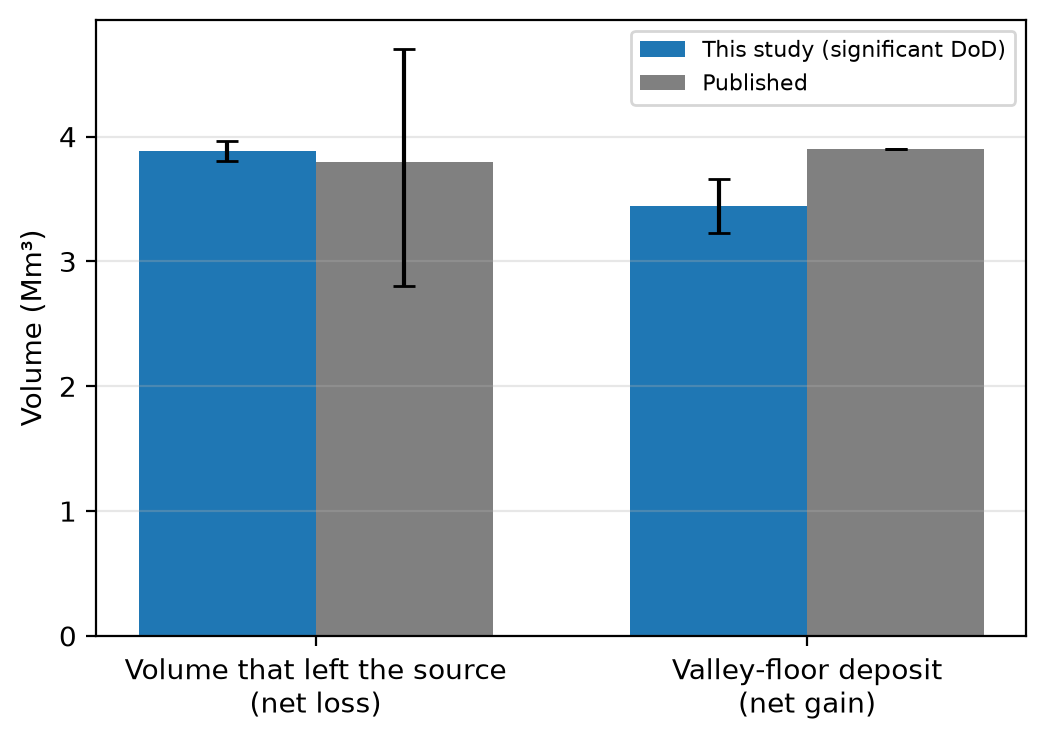

In [8]:
validation = pipeline.step_validate(cfg, change["volumes"])
display(pd.DataFrame(validation["zones"]))
assert validation["passed"], "Zonal volumes differ from the reference run by more than the tolerance"
for path in pipeline.step_figures(cfg, change):
    display(Image(filename=str(path)))